# RV recovery step diagnostics

<span style="color:red">The HISPEC DRP is in active development. Please submit issues and suggestions on the [GitHub](https://github.com/oirlab/HISPEC_DRP).</span>

Track injected-RV recovery through the same densified BT-Settl lte040 spectrum
at every pipeline stage. The default grid is 0, 10, 20, 30, 40, 50 km/s.
Every `StellarRVPrimitive` call keeps **all** finite lines
(`outlier_sigma=1e30`). Run the preamble and section 1 first, then sections
2–4 in order. Section 5 compares whatever steps have finished. Section 6
re-extracts the saved rate maps with simulated wavecals to separate WAVE
association from the extract.

1. **Truth 1D** (section 1): densify the rest-frame template, Doppler-shift it,
   and verify recovered RV ≈ 0 at injected RV = 0.
2. **Native L2** (section 2): paint that shifted 1D onto the echelle WAVE grid.
3. **Rate map → Stage 1** (section 3): ZEMAX/native 2D paint, ZEMAX-matched
   fiberflat, box extract, blaze, recover.
4. **UTR → Stages 0–2** (section 4): simulated ramp and Stage-0 detector cals,
   then the same extract / blaze / CCF path.
5. **Compare** (section 5): which step adds the most bias and RV_ERR.
6. **WAVE vs extract** (section 6): same rate maps, new WAVE (line-ZP and
   extracted comb).


In [1]:
from pathlib import Path

import hispecdrp

print(f"hispecdrp {hispecdrp.__version__} @ {hispecdrp.__file__}")

OUT = Path("/Users/ckilpatrick/rv_recovery_step_diagnostics")
OUT.mkdir(parents=True, exist_ok=True)
print("output:", OUT.resolve())


hispecdrp 0.0.post957+gf8dfcb577.d20260828 @ /Users/ckilpatrick/Dropbox/scripts/python/cursor/HISPEC_DRP/hispecdrp/__init__.py
output: /Users/ckilpatrick/rv_recovery_step_diagnostics


## 1. Truth 1D spectrum and RV=0 check

Densify the packaged lte040 template to R=3e5. At injected RV = 0, paint that
rest-frame 1D onto L2 and recover with every line kept. Then build the
Doppler-shifted truth spectrum for each bulk RV used in sections 2–4.


In [2]:
from hispecdrp.simulations.rv_step_diagnostics import (
    STEP_BULK_RV_KM_S,
    STELLAR_RV_NO_REJECT_KW,
    doppler_shift_spectrum,
    load_densified_template,
    run_step_grid,
    verify_zero_rv_recovery,
)
from hispecdrp.utils.line_mask_utils import (
    paired_line_mask_path_for_template,
    read_mask_generation_meta,
)

FIBER = 1
TEMPLATE = "lte040.0-4.5-0.0a+0.0.BT-Settl.spec.7.h5"
MASK_PATH = paired_line_mask_path_for_template(TEMPLATE, mask_style="ccfopt.delta")
BULK_RV_KM_S = STEP_BULK_RV_KM_S.copy()
meta = read_mask_generation_meta(MASK_PATH) or {}
print(f"mask: {MASK_PATH}")
print(
    f"n_lines={meta.get('n_lines')}  outlier_sigma={STELLAR_RV_NO_REJECT_KW['outlier_sigma']:.0e}"
)
print(f"grid={list(BULK_RV_KM_S)} km/s")

wl_rest, flux_rest = load_densified_template(TEMPLATE)
print(f"truth 1D: n={wl_rest.size}  λ={wl_rest[0]:.4f}–{wl_rest[-1]:.4f}")

verify_zero_rv_recovery(
    template=TEMPLATE,
    mask_path=str(MASK_PATH),
    fiber=FIBER,
)

TRUTH = {
    float(rv): doppler_shift_spectrum(wl_rest, flux_rest, float(rv))
    for rv in BULK_RV_KM_S
}
summaries = {}


mask: /Users/ckilpatrick/Dropbox/scripts/python/cursor/HISPEC_DRP/hispecdrp/data/masks/lte040.0-4.5-0.0a+0.0.BT-Settl.spec.7.ccfopt.delta.mas
n_lines=887  outlier_sigma=1e+30
grid=[np.float64(0.0), np.float64(10.0), np.float64(20.0), np.float64(30.0), np.float64(40.0), np.float64(50.0)] km/s
[2026-10-07T14:23:36][hispecdrp.primitives.utils.spectral_utils:567][INFO]: Normalized spectrum to J=3.05 (AB mag); scale=1.0185e+05 (was 15.57 mag)
truth 1D: n=635113  λ=0.8000 micron–3.0000 micron
RV=0 check: injected=0.000000 m/s  recovered=0.000391 m/s  RV_ERR=0.002586 m/s  bias=3.906170e-04 m/s
|bias| = 3.9062e-04 m/s  (within 1.0000 m/s)


## 2. Paint truth onto L2

Resample each Doppler-shifted 1D spectrum onto the native BSPEC WAVE grid and
recover RV. This is the interpolation-only reference for later steps.


 bulk_km/s    injected_m/s     recovered_m/s    rv_err_m/s      bias_m/s   bias_mm/s
------------------------------------------------------------------------------------
       0.0          0.0000          0.000924      0.106846  9.240248e-04      0.9240
      10.0      10000.0000       9999.961708      0.116520  -3.829181e-02    -38.2918
      20.0      20000.0000      19999.937470      0.115772  -6.253041e-02    -62.5304
      30.0      30000.0000      29999.952494      0.119464  -4.750610e-02    -47.5061
      40.0      40000.0000      39999.914246      0.122715  -8.575360e-02    -85.7536
      50.0      50000.0000      49999.918340      0.119168  -8.165977e-02    -81.6598

L2: mean bias = -5.247 cm/s  std = 2.926 cm/s  mean RV_ERR = 11.675 cm/s


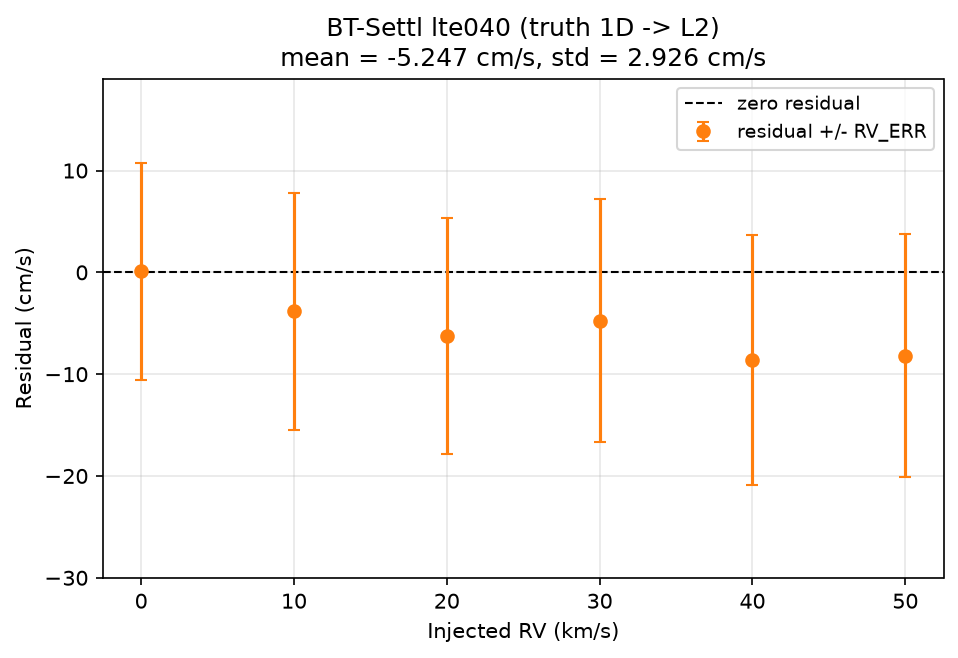

wrote /Users/ckilpatrick/rv_recovery_step_diagnostics/lte040_step_l2.png


In [3]:
from hispecdrp.simulations.rv_step_diagnostics import recover_rv_from_truth_l2


def recover_l2(bulk):
    wl, flux = TRUTH[float(bulk)]
    return recover_rv_from_truth_l2(
        bulk,
        wavelengths=wl,
        flux=flux,
        template=TEMPLATE,
        mask_path=str(MASK_PATH),
        fiber=FIBER,
    )


summaries["L2"] = run_step_grid(
    recover_l2,
    name="L2",
    title="BT-Settl lte040 (truth 1D -> L2)",
    out_path=OUT / "lte040_step_l2.png",
    bulk_rv_km_s=BULK_RV_KM_S,
)


## 3. Rate map → extract → blaze

Paint the same truth 1D onto a native/ZEMAX rate map. Stage-1 traces, WAVE, and
fiberflat come from that ZEMAX model (`prepare_stage1_cals`). Then box-extract,
blaze-correct, and recover RV. The first point builds masters under `OUT`.


 bulk_km/s    injected_m/s     recovered_m/s    rv_err_m/s      bias_m/s   bias_mm/s
------------------------------------------------------------------------------------
JWST Ramp Fitting: Processing row 1 of 4096.
JWST Ramp Fitting: Processing row 2 of 4096.
JWST Ramp Fitting: Processing row 3 of 4096.
JWST Ramp Fitting: Processing row 4 of 4096.
JWST Ramp Fitting: Processing row 5 of 4096.
JWST Ramp Fitting: Processing row 6 of 4096.
JWST Ramp Fitting: Processing row 7 of 4096.
JWST Ramp Fitting: Processing row 8 of 4096.
JWST Ramp Fitting: Processing row 9 of 4096.
JWST Ramp Fitting: Processing row 10 of 4096.
JWST Ramp Fitting: Processing row 11 of 4096.
JWST Ramp Fitting: Processing row 12 of 4096.
JWST Ramp Fitting: Processing row 13 of 4096.
JWST Ramp Fitting: Processing row 14 of 4096.
JWST Ramp Fitting: Processing row 15 of 4096.
JWST Ramp Fitting: Processing row 16 of 4096.
JWST Ramp Fitting: Processing row 17 of 4096.
JWST Ramp Fitting: Processing row 18 of 4096.
JWST Ramp F

/Users/ckilpatrick/Dropbox/scripts/python/cursor/HISPEC_DRP/hispecdrp/simulations/simulate_up_the_ramp.py:128: ResourceWarning: unclosed file <_io.TextIOWrapper name='/Users/ckilpatrick/rv_recovery_step_diagnostics/rate_map_stage1/cals/HB.sim_hdf_stage1.json' mode='r' encoding='utf-8'>
  meta = json.loads(open(paths["meta"], encoding="utf-8").read())


      10.0      10000.0000      10031.289640      2.130798  3.128964e+01  31289.6397


/Users/ckilpatrick/Dropbox/scripts/python/cursor/HISPEC_DRP/hispecdrp/simulations/simulate_up_the_ramp.py:128: ResourceWarning: unclosed file <_io.TextIOWrapper name='/Users/ckilpatrick/rv_recovery_step_diagnostics/rate_map_stage1/cals/HB.sim_hdf_stage1.json' mode='r' encoding='utf-8'>
  meta = json.loads(open(paths["meta"], encoding="utf-8").read())


      20.0      20000.0000      20034.142170      2.036628  3.414217e+01  34142.1699


/Users/ckilpatrick/Dropbox/scripts/python/cursor/HISPEC_DRP/hispecdrp/simulations/simulate_up_the_ramp.py:128: ResourceWarning: unclosed file <_io.TextIOWrapper name='/Users/ckilpatrick/rv_recovery_step_diagnostics/rate_map_stage1/cals/HB.sim_hdf_stage1.json' mode='r' encoding='utf-8'>
  meta = json.loads(open(paths["meta"], encoding="utf-8").read())


      30.0      30000.0000      30033.150325      2.138223  3.315032e+01  33150.3248


/Users/ckilpatrick/Dropbox/scripts/python/cursor/HISPEC_DRP/hispecdrp/simulations/simulate_up_the_ramp.py:128: ResourceWarning: unclosed file <_io.TextIOWrapper name='/Users/ckilpatrick/rv_recovery_step_diagnostics/rate_map_stage1/cals/HB.sim_hdf_stage1.json' mode='r' encoding='utf-8'>
  meta = json.loads(open(paths["meta"], encoding="utf-8").read())


      40.0      40000.0000      40032.455704      2.160105  3.245570e+01  32455.7035


/Users/ckilpatrick/Dropbox/scripts/python/cursor/HISPEC_DRP/hispecdrp/simulations/simulate_up_the_ramp.py:128: ResourceWarning: unclosed file <_io.TextIOWrapper name='/Users/ckilpatrick/rv_recovery_step_diagnostics/rate_map_stage1/cals/HB.sim_hdf_stage1.json' mode='r' encoding='utf-8'>
  meta = json.loads(open(paths["meta"], encoding="utf-8").read())


      50.0      50000.0000      50033.729728      2.004403  3.372973e+01  33729.7276

rate map: mean bias = 3286.890 cm/s  std = 93.855 cm/s  mean RV_ERR = 210.446 cm/s


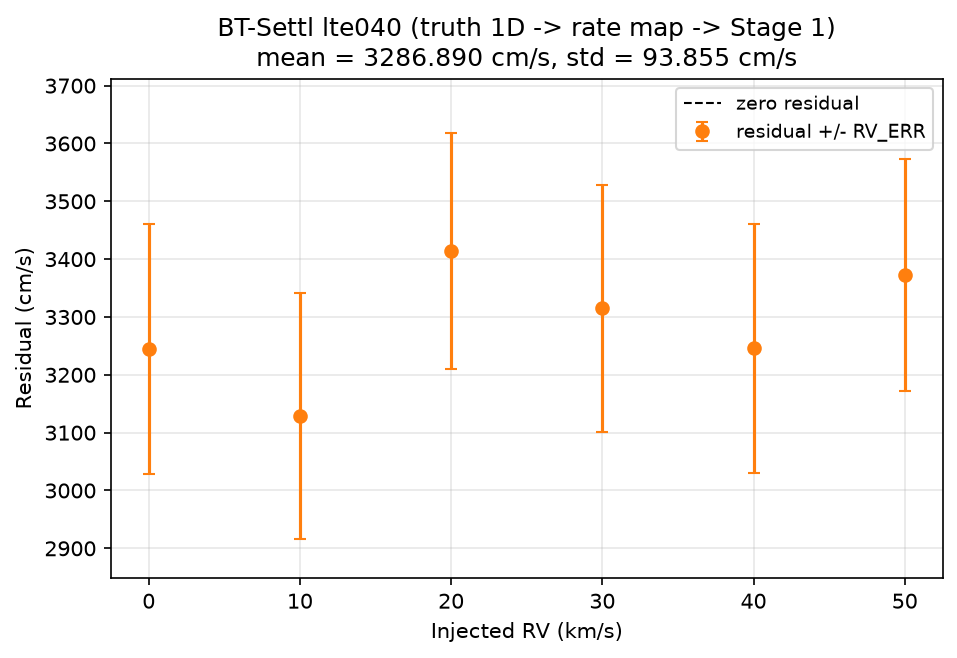

wrote /Users/ckilpatrick/rv_recovery_step_diagnostics/lte040_step_rate_map.png


In [4]:
from hispecdrp.simulations.rv_step_diagnostics import recover_rv_from_truth_rate_map


def recover_rate_map(bulk):
    wl, flux = TRUTH[float(bulk)]
    return recover_rv_from_truth_rate_map(
        bulk,
        wavelengths=wl,
        flux=flux,
        template=TEMPLATE,
        mask_path=str(MASK_PATH),
        output_dir=OUT / "rate_map_stage1",
        fiber=FIBER,
    )


summaries["rate map"] = run_step_grid(
    recover_rate_map,
    name="rate map",
    title="BT-Settl lte040 (truth 1D -> rate map -> Stage 1)",
    out_path=OUT / "lte040_step_rate_map.png",
    bulk_rv_km_s=BULK_RV_KM_S,
)


## 4. UTR → Stages 0–2

Realize each truth 1D as a simulated up-the-ramp exposure with matching 2D
Stage-0 calibration frames, run Stage 0, then the same Stage 1 / blaze / CCF
path as section 3. Poisson noise is off so residual scatter isolates the ramp
fit. Each iteration deletes its working directory after the RV is recorded.


 bulk_km/s    injected_m/s     recovered_m/s    rv_err_m/s      bias_m/s   bias_mm/s
------------------------------------------------------------------------------------


/Users/ckilpatrick/Dropbox/scripts/python/cursor/HISPEC_DRP/hispecdrp/utils/parallelization_utils.py:66: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  numpy_array.shape = shape


JWST Ramp Fitting: Processing row 1 of 4096.
JWST Ramp Fitting: Processing row 2 of 4096.
JWST Ramp Fitting: Processing row 3 of 4096.
JWST Ramp Fitting: Processing row 4 of 4096.
JWST Ramp Fitting: Processing row 5 of 4096.
JWST Ramp Fitting: Processing row 6 of 4096.
JWST Ramp Fitting: Processing row 7 of 4096.
JWST Ramp Fitting: Processing row 8 of 4096.
JWST Ramp Fitting: Processing row 9 of 4096.
JWST Ramp Fitting: Processing row 10 of 4096.
JWST Ramp Fitting: Processing row 11 of 4096.
JWST Ramp Fitting: Processing row 12 of 4096.
JWST Ramp Fitting: Processing row 13 of 4096.
JWST Ramp Fitting: Processing row 14 of 4096.
JWST Ramp Fitting: Processing row 15 of 4096.
JWST Ramp Fitting: Processing row 16 of 4096.
JWST Ramp Fitting: Processing row 17 of 4096.
JWST Ramp Fitting: Processing row 18 of 4096.
JWST Ramp Fitting: Processing row 19 of 4096.
JWST Ramp Fitting: Processing row 20 of 4096.
JWST Ramp Fitting: Processing row 21 of 4096.
JWST Ramp Fitting: Processing row 22 of 409

/Users/ckilpatrick/Dropbox/scripts/python/cursor/HISPEC_DRP/hispecdrp/utils/parallelization_utils.py:66: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  numpy_array.shape = shape


JWST Ramp Fitting: Processing row 1 of 4096.
JWST Ramp Fitting: Processing row 2 of 4096.
JWST Ramp Fitting: Processing row 3 of 4096.
JWST Ramp Fitting: Processing row 4 of 4096.
JWST Ramp Fitting: Processing row 5 of 4096.
JWST Ramp Fitting: Processing row 6 of 4096.
JWST Ramp Fitting: Processing row 7 of 4096.
JWST Ramp Fitting: Processing row 8 of 4096.
JWST Ramp Fitting: Processing row 9 of 4096.
JWST Ramp Fitting: Processing row 10 of 4096.
JWST Ramp Fitting: Processing row 11 of 4096.
JWST Ramp Fitting: Processing row 12 of 4096.
JWST Ramp Fitting: Processing row 13 of 4096.
JWST Ramp Fitting: Processing row 14 of 4096.
JWST Ramp Fitting: Processing row 15 of 4096.
JWST Ramp Fitting: Processing row 16 of 4096.
JWST Ramp Fitting: Processing row 17 of 4096.
JWST Ramp Fitting: Processing row 18 of 4096.
JWST Ramp Fitting: Processing row 19 of 4096.
JWST Ramp Fitting: Processing row 20 of 4096.
JWST Ramp Fitting: Processing row 21 of 4096.
JWST Ramp Fitting: Processing row 22 of 409

/Users/ckilpatrick/Dropbox/scripts/python/cursor/HISPEC_DRP/hispecdrp/simulations/simulate_up_the_ramp.py:128: ResourceWarning: unclosed file <_io.TextIOWrapper name='/Users/ckilpatrick/rv_recovery_step_diagnostics/ramp_stage0/cals/HB.sim_hdf_stage1.json' mode='r' encoding='utf-8'>
  meta = json.loads(open(paths["meta"], encoding="utf-8").read())
/Users/ckilpatrick/Dropbox/scripts/python/cursor/HISPEC_DRP/hispecdrp/utils/parallelization_utils.py:66: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  numpy_array.shape = shape


... (5 outputs left out)

/Users/ckilpatrick/Dropbox/scripts/python/cursor/HISPEC_DRP/hispecdrp/simulations/simulate_up_the_ramp.py:128: ResourceWarning: unclosed file <_io.TextIOWrapper name='/Users/ckilpatrick/rv_recovery_step_diagnostics/ramp_stage0/cals/HB.sim_hdf_stage1.json' mode='r' encoding='utf-8'>
  meta = json.loads(open(paths["meta"], encoding="utf-8").read())
/Users/ckilpatrick/Dropbox/scripts/python/cursor/HISPEC_DRP/hispecdrp/utils/parallelization_utils.py:66: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  numpy_array.shape = shape


JWST Ramp Fitting: Processing row 1 of 4096.
JWST Ramp Fitting: Processing row 2 of 4096.
JWST Ramp Fitting: Processing row 3 of 4096.
JWST Ramp Fitting: Processing row 4 of 4096.
JWST Ramp Fitting: Processing row 5 of 4096.
JWST Ramp Fitting: Processing row 6 of 4096.
JWST Ramp Fitting: Processing row 7 of 4096.
JWST Ramp Fitting: Processing row 8 of 4096.
JWST Ramp Fitting: Processing row 9 of 4096.
JWST Ramp Fitting: Processing row 10 of 4096.
JWST Ramp Fitting: Processing row 11 of 4096.
JWST Ramp Fitting: Processing row 12 of 4096.
JWST Ramp Fitting: Processing row 13 of 4096.
JWST Ramp Fitting: Processing row 14 of 4096.
JWST Ramp Fitting: Processing row 15 of 4096.
JWST Ramp Fitting: Processing row 16 of 4096.
JWST Ramp Fitting: Processing row 17 of 4096.
JWST Ramp Fitting: Processing row 18 of 4096.
JWST Ramp Fitting: Processing row 19 of 4096.
JWST Ramp Fitting: Processing row 20 of 4096.
JWST Ramp Fitting: Processing row 21 of 4096.
JWST Ramp Fitting: Processing row 22 of 409

/Users/ckilpatrick/Dropbox/scripts/python/cursor/HISPEC_DRP/hispecdrp/simulations/simulate_up_the_ramp.py:128: ResourceWarning: unclosed file <_io.TextIOWrapper name='/Users/ckilpatrick/rv_recovery_step_diagnostics/ramp_stage0/cals/HB.sim_hdf_stage1.json' mode='r' encoding='utf-8'>
  meta = json.loads(open(paths["meta"], encoding="utf-8").read())
/Users/ckilpatrick/Dropbox/scripts/python/cursor/HISPEC_DRP/hispecdrp/utils/parallelization_utils.py:66: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  numpy_array.shape = shape


JWST Ramp Fitting: Processing row 1 of 4096.
JWST Ramp Fitting: Processing row 2 of 4096.
JWST Ramp Fitting: Processing row 3 of 4096.
JWST Ramp Fitting: Processing row 4 of 4096.
JWST Ramp Fitting: Processing row 5 of 4096.
JWST Ramp Fitting: Processing row 6 of 4096.
JWST Ramp Fitting: Processing row 7 of 4096.
JWST Ramp Fitting: Processing row 8 of 4096.
JWST Ramp Fitting: Processing row 9 of 4096.
JWST Ramp Fitting: Processing row 10 of 4096.
JWST Ramp Fitting: Processing row 11 of 4096.
JWST Ramp Fitting: Processing row 12 of 4096.
JWST Ramp Fitting: Processing row 13 of 4096.
JWST Ramp Fitting: Processing row 14 of 4096.
JWST Ramp Fitting: Processing row 15 of 4096.
JWST Ramp Fitting: Processing row 16 of 4096.
JWST Ramp Fitting: Processing row 17 of 4096.
JWST Ramp Fitting: Processing row 18 of 4096.
JWST Ramp Fitting: Processing row 19 of 4096.
JWST Ramp Fitting: Processing row 20 of 4096.
JWST Ramp Fitting: Processing row 21 of 4096.
JWST Ramp Fitting: Processing row 22 of 409

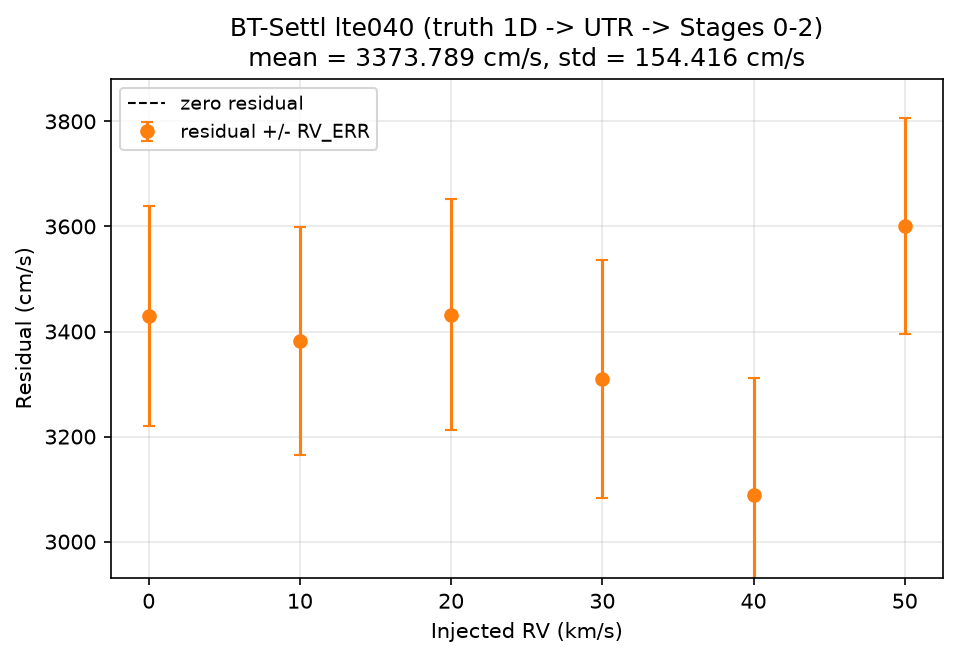

wrote /Users/ckilpatrick/rv_recovery_step_diagnostics/lte040_step_utr.png


In [5]:
from hispecdrp.simulations.rv_step_diagnostics import recover_rv_from_truth_ramp


def recover_ramp(bulk):
    wl, flux = TRUTH[float(bulk)]
    return recover_rv_from_truth_ramp(
        bulk,
        wavelengths=wl,
        flux=flux,
        template=TEMPLATE,
        mask_path=str(MASK_PATH),
        output_dir=OUT / "ramp_stage0",
        fiber=FIBER,
    )


summaries["UTR + Stage 0-2"] = run_step_grid(
    recover_ramp,
    name="UTR + Stage 0-2",
    title="BT-Settl lte040 (truth 1D -> UTR -> Stages 0-2)",
    out_path=OUT / "lte040_step_utr.png",
    bulk_rv_km_s=BULK_RV_KM_S,
)


## 5. Compare steps

Mean residual, residual scatter, and mean formal `RV_ERR` for each completed
step. Increments (`Δ`) show what the next stage added. The largest increment
is the step that degrades the measurement the most.


step                             mean_bias      std_bias   mean_RV_ERR    Δmean_bias          Δstd       ΔRV_ERR
----------------------------------------------------------------------------------------------------------------
                        (m/s)         (m/s)         (m/s)         (m/s)         (m/s)         (m/s)
L2                               -0.052470      0.029262      0.116747           nan           nan           nan
rate map                         32.868896      0.938548      2.104462     32.921366      0.909286      1.987714
UTR + Stage 0-2                  33.737891      1.544165      2.167497      0.868995      0.605617      0.063036

Largest increment: rate map  Δmean=32.9214 m/s  Δstd=0.9093 m/s  ΔRV_ERR=1.9877 m/s


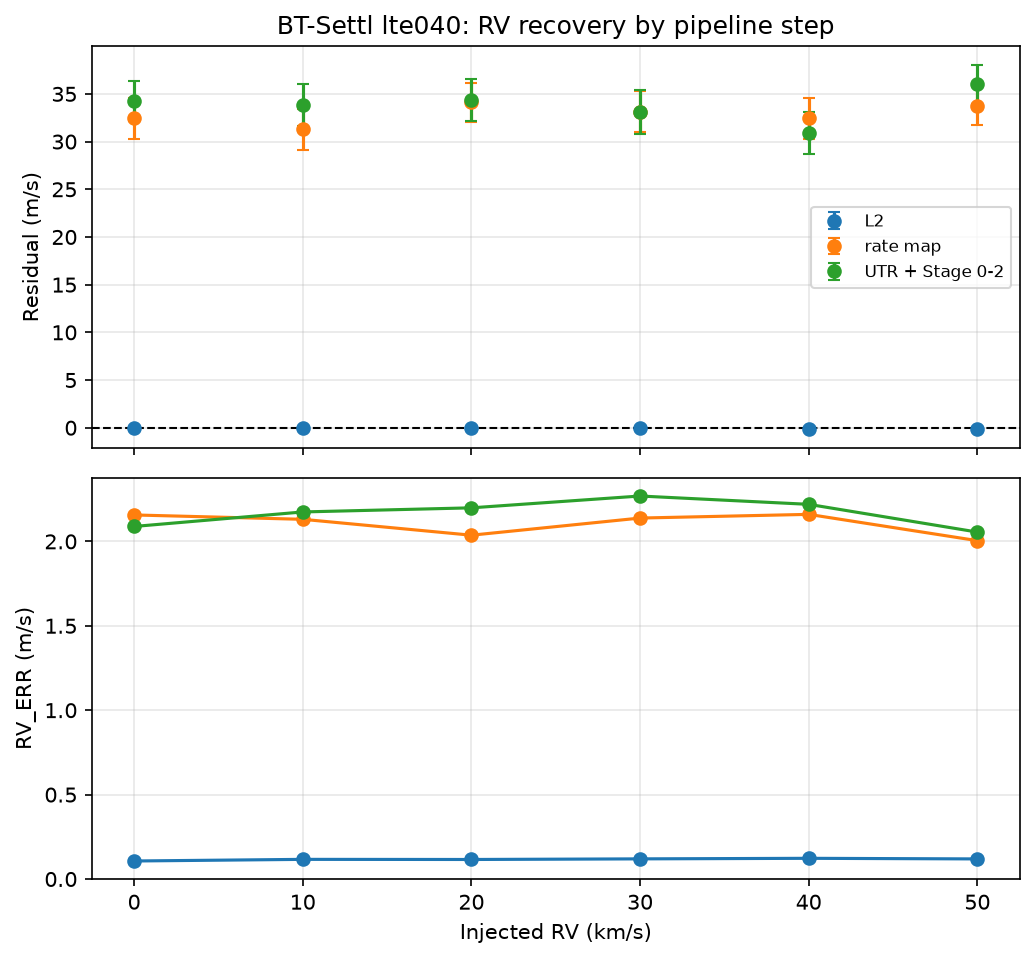

wrote /Users/ckilpatrick/rv_recovery_step_diagnostics/lte040_step_comparison.png


In [6]:
from hispecdrp.simulations.plotting import plot_rv_step_comparison
from hispecdrp.simulations.rv_step_diagnostics import compare_step_summaries

increments = compare_step_summaries(summaries)
cmp = plot_rv_step_comparison(
    summaries,
    title="BT-Settl lte040: RV recovery by pipeline step",
    out_path=OUT / "lte040_step_comparison.png",
)
if cmp.get("out_path"):
    print("wrote", cmp["out_path"])


## 6. Separate WAVE association from extraction

The rate-map jump is a nearly constant +33 m/s zeropoint. That can be a
wrong WAVE attached to a good extract, or an extract that shifts line
centroids. Re-extract the saved rate maps with two simulated wavecals:

1. **Line-ZP WAVE** — absorption-line zeropoint on the RV=0 rate map
   (`known_rv=0`). If the 0–50 km/s grid then matches the L2 residuals,
   the box extract is fine and geometric WAVE was sampled at deposit
   centers, not at the extracted PSF centroid.
2. **Comb WAVE** — paint an emission comb, box-extract it the same way as
   science, and fit `λ(pixel)`. If this also removes the +33 m/s, the
   bias is wavelength association (PSF vs deposit), not a broken stellar
   extract.


In [ ]:
import numpy as np
from astropy.io import fits

from hispecdrp.simulations.ideal_spectrum_rv import prepare_stage1_cals
from hispecdrp.simulations.plotting import plot_rv_step_comparison
from hispecdrp.simulations.rv_step_diagnostics import (
    compare_step_summaries,
    recover_rv_from_saved_rate_map,
    run_step_grid,
    saved_rate_map_path,
    wavesol_from_extracted_comb,
    wavesol_from_line_zeropoint,
)

RATE_PARENT = OUT / "rate_map_stage1"
rate0_path = saved_rate_map_path(RATE_PARENT, 0.0)
if not rate0_path.is_file():
    raise FileNotFoundError(f"Run section 3 first; missing {rate0_path}")
rate0 = np.asarray(fits.getdata(rate0_path), dtype=float)

print("Line-ZP WAVE from the RV=0 science rate map ...")
wavesol_zp, zp_info = wavesol_from_line_zeropoint(
    rate0,
    fiber=FIBER,
    known_rv_m_s=0.0,
    poly_deg=0,
)
print(f"line-ZP median_dv = {zp_info.get('median_dv_m_s')} m/s  n_orders={zp_info.get('per_fiber', {}).get(FIBER, {}).get('n_orders')}")

print("Comb WAVE from a 1D box-extracted emission comb ...")
wavesol_comb, comb_info = wavesol_from_extracted_comb(fiber=FIBER)
print(
    f"median PSF-centroid residual vs deposit WAVE = "
    f"{comb_info['median_centroid_residual_m_s']:.3f} m/s  "
    f"n_orders_fit={comb_info['n_orders_fit']}"
)

cals = prepare_stage1_cals(RATE_PARENT, rate0, fiber=FIBER)


def recover_with_wavesol(wavesol):
    def recover(bulk):
        path = saved_rate_map_path(RATE_PARENT, bulk)
        rate = np.asarray(fits.getdata(path), dtype=float)
        return recover_rv_from_saved_rate_map(
            bulk,
            rate_map=rate,
            template=TEMPLATE,
            mask_path=str(MASK_PATH),
            output_dir=OUT / "wave_split",
            wavesol=wavesol,
            fiber=FIBER,
            stage1_cals=cals,
        )

    return recover


summaries["rate map + line-ZP WAVE"] = run_step_grid(
    recover_with_wavesol(wavesol_zp),
    name="rate map + line-ZP WAVE",
    title="BT-Settl lte040 (rate map + absorption-line WAVE ZP)",
    out_path=OUT / "lte040_step_rate_map_linezp.png",
    bulk_rv_km_s=BULK_RV_KM_S,
)
summaries["rate map + comb WAVE"] = run_step_grid(
    recover_with_wavesol(wavesol_comb),
    name="rate map + comb WAVE",
    title="BT-Settl lte040 (rate map + extracted-comb WAVE)",
    out_path=OUT / "lte040_step_rate_map_comb.png",
    bulk_rv_km_s=BULK_RV_KM_S,
)

split = {
    k: summaries[k]
    for k in ("L2", "rate map", "rate map + line-ZP WAVE", "rate map + comb WAVE")
    if k in summaries
}
compare_step_summaries(split)
cmp = plot_rv_step_comparison(
    split,
    title="WAVE vs extract: rate-map RV with alternate wavecals",
    out_path=OUT / "lte040_step_wave_vs_extract.png",
)
if cmp.get("out_path"):
    print("wrote", cmp["out_path"])
